In [30]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import math
from scipy.stats import skew

In [3]:
df = pd.read_csv(r'Data\amz_uk_price_prediction_dataset.csv')
display(df)

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


### Part 1: Understanding Product Categories

**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

1. **Frequency Tables**:
    - Generate a frequency table for the product `category`.
    - Which are the top 5 most listed product categories?
    The 5 most listed categories are: 
        1. Sports & Outdoors, 
        2. Beauty
        3. Handame Clothing, Shoes & Accesories
        4. Bath & Body
        5. Birthday Gifts


In [4]:
df.dtypes

uid                    int64
asin                  object
title                 object
stars                float64
reviews                int64
price                float64
isBestSeller            bool
boughtInLastMonth      int64
category              object
dtype: object

In [5]:
df_numerical = df.select_dtypes('number')
display(df_numerical.head(5))
df_categorical = df.select_dtypes('object')
display(df_categorical.head(5))

,uid,stars,reviews,price,boughtInLastMonth
0,1,4.7,15308,21.99,0
1,2,4.7,98099,23.99,0
2,3,4.7,15308,21.99,0
3,4,4.7,7205,31.99,0
4,5,4.6,1881,17.99,0


,asin,title,category
0,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",Hi-Fi Speakers
1,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",Hi-Fi Speakers
2,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",Hi-Fi Speakers
3,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",Hi-Fi Speakers
4,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,Hi-Fi Speakers


In [6]:
freq_table = df_categorical['category'].value_counts()
prop_table = df_categorical['category'].value_counts(normalize=True)
frequency_table = pd.concat([freq_table,prop_table], axis=1).reset_index()

display(frequency_table.sort_values(by=['count', 'proportion'], ascending=False).head(5))

,category,count,proportion
0,Sports & Outdoors,836265,0.342219
1,Beauty,19312,0.007903
2,"Handmade Clothing, Shoes & Accessories",19229,0.007869
3,Bath & Body,19092,0.007813
4,Birthday Gifts,18978,0.007766


2. **Visualizations**:
    - Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
    - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?
        Yes, sports & outdoors dominate the listings

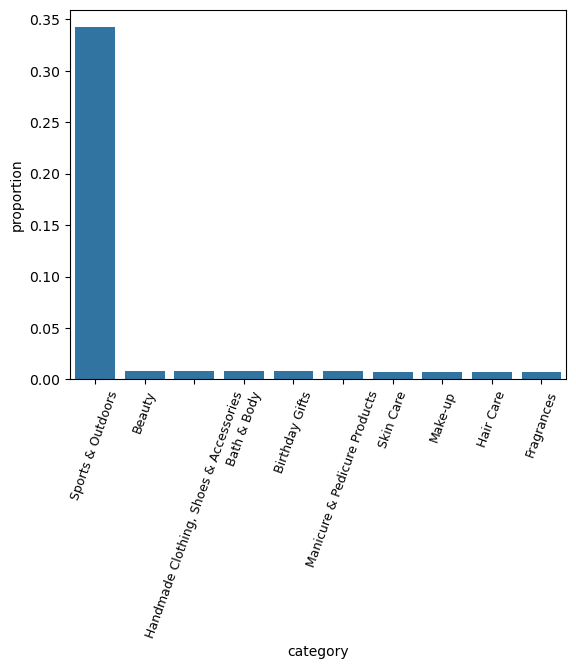

In [7]:
sns.barplot(x = frequency_table['category'].head(10),
            y = frequency_table['proportion'].head(10))

plt.xticks(rotation=70, fontsize=9)
plt.show()

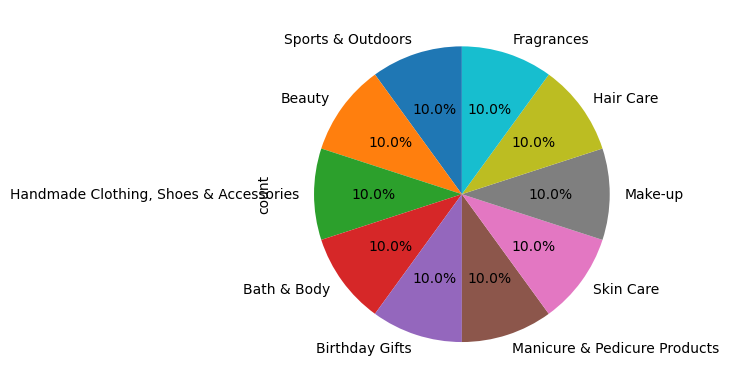

In [8]:
frequency_table['category'].head(10).value_counts().plot.pie(autopct = '%1.1f%%', startangle = 90, color = sns.color_palette('Set3'))
plt.show()

### Part 2: Delving into Product Pricing

**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `price` of products.
    - What's the average price point of products listed? How does this compare with the most common price point (mode)? Average price is 89,24, although the mode is 9,99 which mean that there are some outliers


In [9]:
df_numerical

,uid,stars,reviews,price,boughtInLastMonth
0,1,4.7,15308,21.99,0
1,2,4.7,98099,23.99,0
2,3,4.7,15308,21.99,0
3,4,4.7,7205,31.99,0
4,5,4.6,1881,17.99,0
...,...,...,...,...,...
2443646,2828589,0.0,0,22.34,0
2443647,2828590,0.0,0,97.99,0
2443648,2828591,0.0,0,52.99,0
2443649,2828592,4.3,404,79.99,0


In [10]:
price_df = df_numerical['price'].sort_values(ascending=True)

In [11]:
price_mean = price_df.mean()
price_median = price_df.median()
price_mode = price_df.mode()

print(f"""mean is {price_mean}
median is {price_median}
mode is {price_mode}
            """)

mean is 89.24380943923661
median is 19.09
mode is 0    9.99
Name: price, dtype: float64
            


In [28]:
price_df.describe()

count    2.443651e+06
mean     8.924381e+01
std      3.456089e+02
min      0.000000e+00
25%      9.990000e+00
50%      1.909000e+01
75%      4.599000e+01
max      1.000000e+05
Name: price, dtype: float64

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, range, and interquartile range for product `price`.
    - How varied are the product prices? Are there any indicators of a significant spread in prices? The products are very varied in prices according to the high value of the interquartile range and the standard deviation.

In [13]:
variance = df_numerical['price'].var()
std = math.sqrt(variance)
price_range = df_numerical['price'].min() - df_numerical['price'].max()
q2 = price_df.median()
q1 = price_df[price_df < q2].median()
q3 = price_df[price_df > q2].median()
interquartile_range = q3 - q1
print(f""""
variances--> {variance}
std--> {std}
range --> {price_range}
q1 ---> {q1}
q2 ---> {q2}
q3 ---> {q3}
interquartile range ---. {interquartile_range}
      """)

"
variances--> 119445.48532256528
std--> 345.60886175352226
range --> -100000.0
q1 ---> 9.99
q2 ---> 19.09
q3 ---> 45.99
interquartile range ---. 36.0
      


3. **Visualizations**:
    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*. The distribution is hard to see probably due to ouliers. It would be convinient to create bins.
    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 

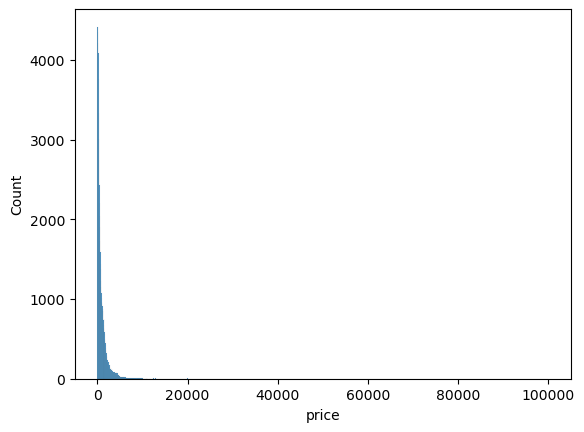

In [14]:
group_df = df_numerical.groupby(['price']).agg(count = ('uid','count')).reset_index()

sns.histplot(data=group_df, x=group_df['price'])
plt.show()

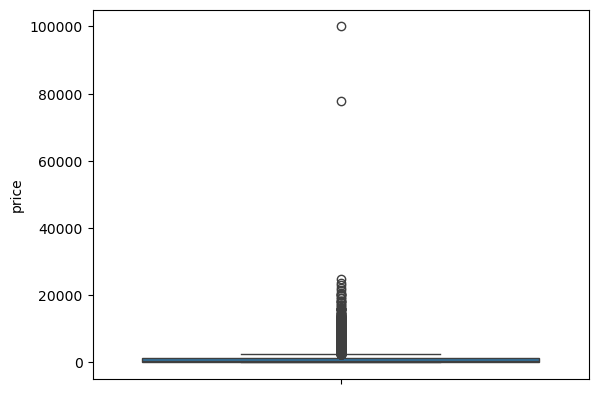

In [16]:
sns.boxplot(data=group_df, y=group_df['price'])
plt.show()

### Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `rating` of products.
    - How do customers generally rate products? Is there a common trend?

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, and interquartile range for product `rating`.
    - Are the ratings consistent, or is there a wide variation in customer feedback?

3. **Shape of the Distribution**:
    - Calculate the skewness and kurtosis for the `rating` column. 
    - Are the ratings normally distributed, or do they lean towards higher or lower values?

4. **Visualizations**:
    - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?


In [19]:
df_numerical

,uid,stars,reviews,price,boughtInLastMonth
0,1,4.7,15308,21.99,0
1,2,4.7,98099,23.99,0
2,3,4.7,15308,21.99,0
3,4,4.7,7205,31.99,0
4,5,4.6,1881,17.99,0
...,...,...,...,...,...
2443646,2828589,0.0,0,22.34,0
2443647,2828590,0.0,0,97.99,0
2443648,2828591,0.0,0,52.99,0
2443649,2828592,4.3,404,79.99,0


In [21]:
rating_df = df_numerical['reviews'].sort_values(ascending=True)

In [26]:
rating_mean = rating_df.mean()
rating_median = rating_df.median()
rating_mode = rating_df.mode()

print(f"""mean is {rating_mean}
median is {rating_median}
mode is {rating_mode}
            """)

mean is 480.6277569914853
median is 0.0
mode is 0    0
Name: reviews, dtype: int64
            


In [23]:
variance = df_numerical['reviews'].var()
std = math.sqrt(variance)
rating_range = df_numerical['reviews'].min() - df_numerical['reviews'].max()
q2 = rating_df.median()
q1 = rating_df[rating_df < q2].median()
q3 = rating_df[rating_df > q2].median()
interquartile_range = q3 - q1
print(f""""
variances--> {variance}
std--> {std}
range --> {price_range}
q1 ---> {q1}
q2 ---> {q2}
q3 ---> {q3}
interquartile range ---. {interquartile_range}
      """)

"
variances--> 35332611.92181505
std--> 5944.124150942261
range --> -100000.0
q1 ---> nan
q2 ---> 0.0
q3 ---> 60.0
interquartile range ---. nan
      


In [ ]:
skewdness = skew(rating_df, axis=0, bias=True)

102.81775868232056

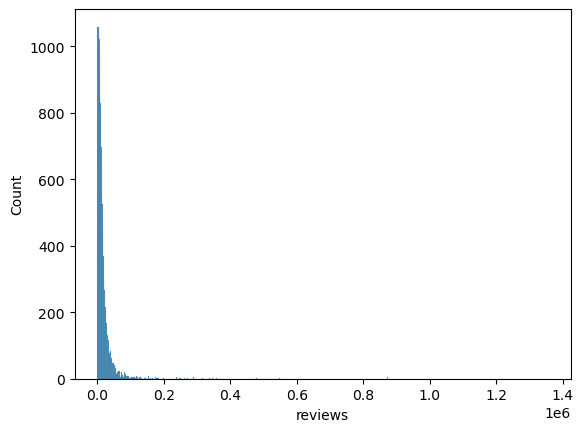

In [33]:
group_df = df.groupby(['reviews']).agg(count = ('reviews','count')).reset_index()

sns.histplot(data=group_df, x=group_df['reviews'])
plt.show()